# Regression Track — Notebook 03
# 5. Exploratory Data Analysis

**Input:** `artifacts/reg_02_audited.joblib`
**Output:** `artifacts/reg_03_eda.joblib` (data unchanged; EDA does not modify data)

---

### Purpose

EDA is where we form hypotheses about *which* features matter and *what shape*
their relationship with demand takes. Those hypotheses then justify the
feature engineering in Notebook 05 and the choice of model families in
Notebook 07.

Every figure below is followed by a Markdown cell separating what we **see**
(observation) from what we **conclude** (interpretation).

**Sections:** A target · B numeric features · C categorical features ·
D correlation · E feature-vs-target · F time patterns.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    load_artifact,
    plot_correlation_heatmap,
    plot_numeric_distributions,
    save_artifact,
    save_figure,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
set_plot_style()

bike_df = load_artifact("reg_02_audited")

# A working copy with calendar columns, used for the time-based plots only.
# NOTE: these are exploratory columns. The real, model-facing feature
# engineering happens in Notebook 05 — this is analysis, not preprocessing.
eda = bike_df.copy()
eda["DateParsed"] = pd.to_datetime(eda["Date"], format="%d/%m/%Y")
eda["Month"] = eda["DateParsed"].dt.month
eda["MonthName"] = eda["DateParsed"].dt.strftime("%b")
eda["DayOfWeek"] = eda["DateParsed"].dt.dayofweek
eda["DayName"] = eda["DateParsed"].dt.day_name().str[:3]
eda["IsWeekend"] = (eda["DayOfWeek"] >= 5).map({True: "Weekend", False: "Weekday"})

TARGET = "Rented Bike Count"
NUMERIC_FEATURES = [
    "Hour", "Temperature(°C)", "Humidity(%)", "Wind speed (m/s)",
    "Visibility (10m)", "Dew point temperature(°C)",
    "Solar Radiation (MJ/m2)", "Rainfall(mm)", "Snowfall (cm)",
]
CATEGORICAL_FEATURES = ["Seasons", "Holiday", "Functioning Day"]

print(f"\nEDA frame shape: {eda.shape}")

[loaded] artifacts/reg_02_audited.joblib

EDA frame shape: (8760, 20)


---
## 5.A Target distribution

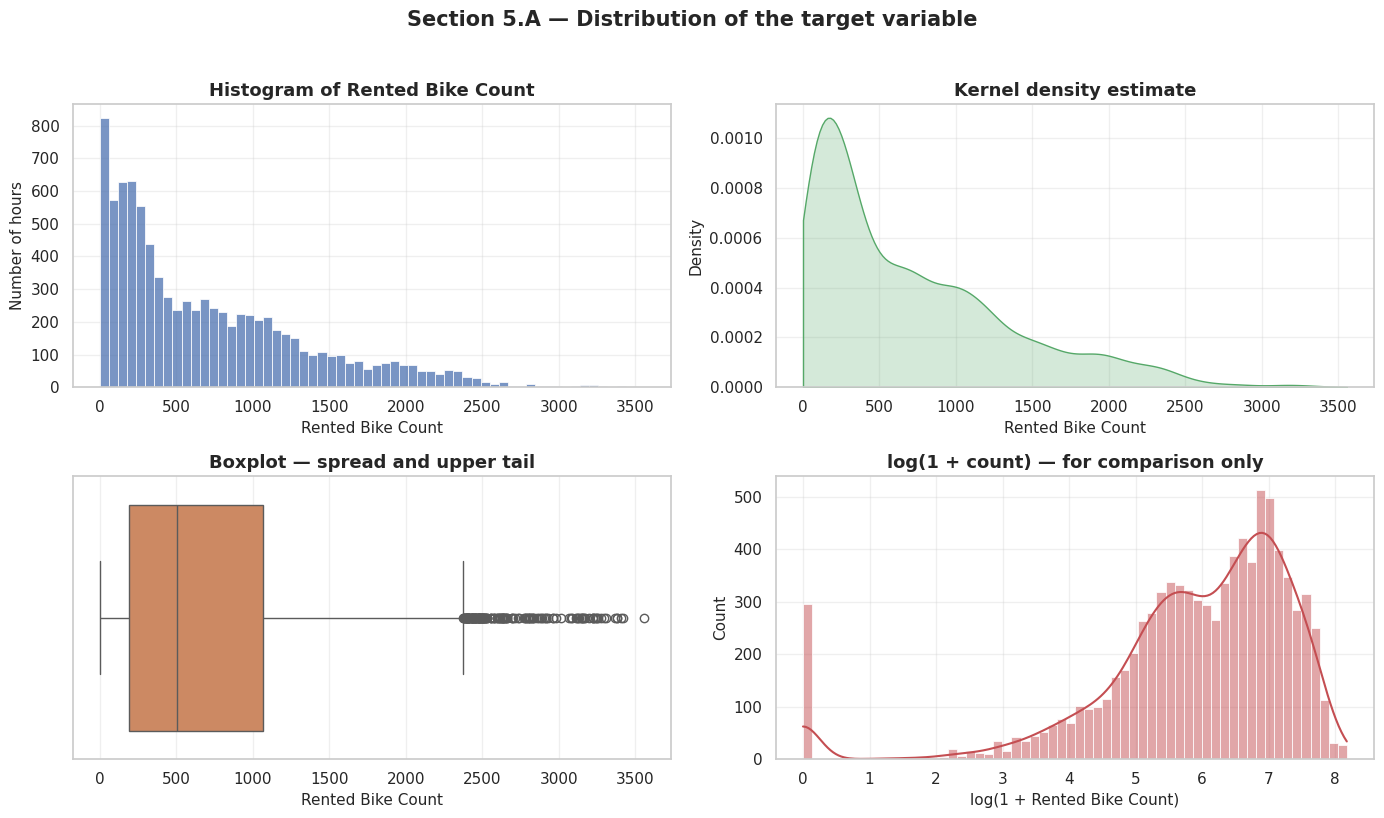

Skewness, raw target (all rows)              : 1.153
Skewness, log(1 + target) (all rows)         : -1.832
Skewness, raw target (operating hours only)  : 1.140
Skewness, log(1 + target) (operating only)   : -0.770


In [2]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.histplot(bike_df[TARGET], bins=60, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Histogram of Rented Bike Count")
axes[0, 0].set_xlabel("Rented Bike Count")
axes[0, 0].set_ylabel("Number of hours")

sns.kdeplot(bike_df[TARGET], fill=True, ax=axes[0, 1], color="#55A868", cut=0)
axes[0, 1].set_title("Kernel density estimate")
axes[0, 1].set_xlabel("Rented Bike Count")

sns.boxplot(x=bike_df[TARGET], ax=axes[1, 0], color="#DD8452")
axes[1, 0].set_title("Boxplot — spread and upper tail")
axes[1, 0].set_xlabel("Rented Bike Count")

log_target = np.log1p(bike_df[TARGET])
sns.histplot(log_target, bins=60, kde=True, ax=axes[1, 1], color="#C44E52")
axes[1, 1].set_title("log(1 + count) — for comparison only")
axes[1, 1].set_xlabel("log(1 + Rented Bike Count)")

fig.suptitle("Section 5.A — Distribution of the target variable",
             y=1.02, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("reg_eda_target_distribution", fig)
plt.show()

operating_target = bike_df.loc[bike_df["Functioning Day"] == "Yes", TARGET]
print(f"Skewness, raw target (all rows)              : {bike_df[TARGET].skew():.3f}")
print(f"Skewness, log(1 + target) (all rows)         : {log_target.skew():.3f}")
print(f"Skewness, raw target (operating hours only)  : {operating_target.skew():.3f}")
print(f"Skewness, log(1 + target) (operating only)   : {np.log1p(operating_target).skew():.3f}")

**Observation.** The raw histogram falls away steeply from a large mass of
low-demand hours, with a thin tail stretching past 3,000. The boxplot marks a
substantial number of points above the upper whisker. The log-transformed
panel does **not** simply fix the skew: it swings it from ≈ +1.15 to ≈ −1.83,
because the 295 structural zeros identified in Notebook 02 become a hard spike
at log(1) = 0. Restricted to operating hours only, the log-skew is far milder.

**Interpretation.** Three consequences:

1. **RMSE will be noticeably larger than MAE** in every results table, because
   the tail hours generate large squared errors.
2. The points above the boxplot whisker are **peak commuting hours in good
   weather**, not sensor faults. They are the most operationally important
   hours in the dataset. Notebook 04 examines them properly before deciding
   on any treatment.
3. We deliberately **do not apply a log transform**. Two reasons. First, the
   printed skew values show it is not the clean fix it is often assumed to be
   while the structural zeros are still present. Second, and more importantly,
   the assignment asks us to predict and report on `Rented Bike Count`, and
   R²/RMSE computed in log space are not comparable to R²/RMSE in count space.
   Keeping the raw target keeps all ten models honestly comparable and keeps
   MAE directly readable as "bikes we were wrong by".

---
## 5.B Distributions of the numerical features

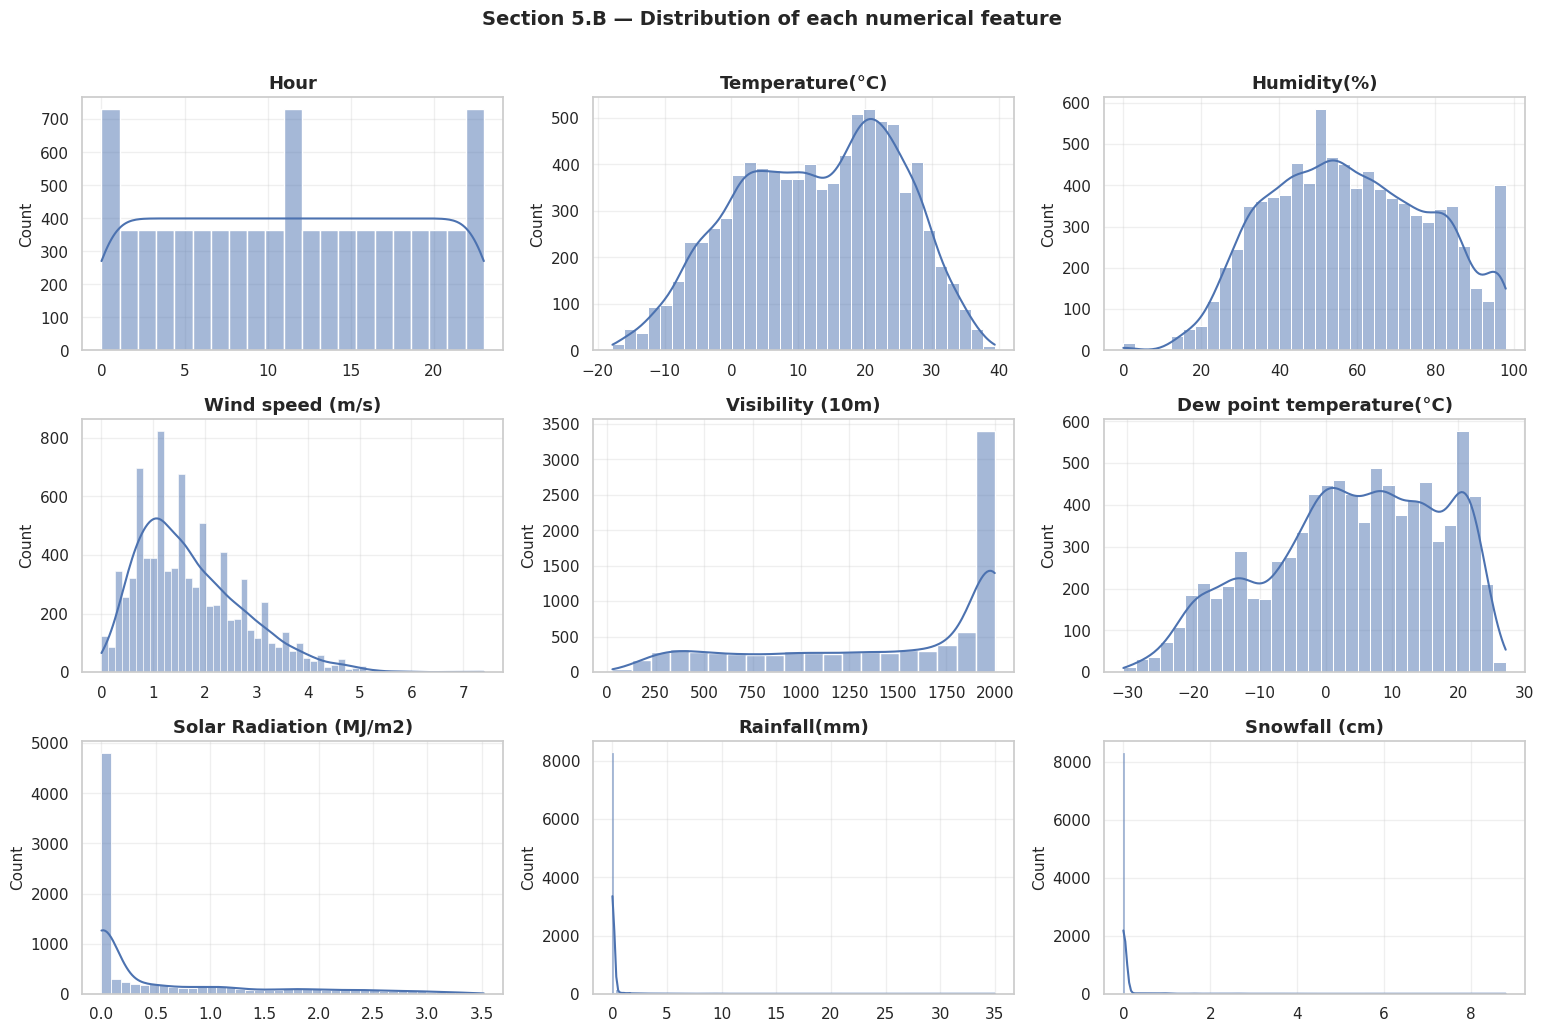

In [3]:
fig = plot_numeric_distributions(
    bike_df, NUMERIC_FEATURES, ncols=3,
    title="Section 5.B — Distribution of each numerical feature",
)
save_figure("reg_eda_feature_distributions", fig)
plt.show()

In [4]:
skew_table = (
    bike_df[NUMERIC_FEATURES]
    .skew()
    .rename("Skewness")
    .to_frame()
    .assign(**{"% exactly zero": [100 * (bike_df[c] == 0).mean() for c in NUMERIC_FEATURES]})
    .round(3)
    .sort_values("Skewness", ascending=False)
)
section("FEATURE SKEWNESS AND ZERO-INFLATION")
print(skew_table.to_string())

FEATURE SKEWNESS AND ZERO-INFLATION
                           Skewness  % exactly zero
Rainfall(mm)                 14.533          93.973
Snowfall (cm)                 8.441          94.943
Solar Radiation (MJ/m2)       1.504          49.087
Wind speed (m/s)              0.891           0.845
Humidity(%)                   0.060           0.194
Hour                          0.000           4.167
Temperature(°C)              -0.198           0.240
Dew point temperature(°C)    -0.367           0.685
Visibility (10m)             -0.702           0.000


**Observation.** The nine numeric features fall into three clearly different
shapes:

* **Near-uniform:** `Hour` — by construction, every hour appears 365 times.
* **Roughly bell-shaped:** `Temperature`, `Humidity`, `Dew point` — these
  behave like ordinary continuous measurements.
* **Extremely right-skewed and zero-inflated:** `Rainfall` (skew ≈ 14),
  `Snowfall` (≈ 8), `Solar Radiation` (≈ 1.5). `Visibility` is the mirror
  image — piled up against its 2000 ceiling.

**Interpretation.** The zero-inflated weather variables are the ones that will
cause trouble for linear models. A linear model has to represent "rain
suppresses demand" as a single constant slope, but the real effect is closer
to a step: *any* rain suppresses demand sharply, and whether it is 2 mm or
20 mm matters much less. A decision tree can express that with one split
(`Rainfall > 0`), which is a concrete, checkable reason to expect tree-based
models to outperform here. Scaling will be essential for the distance- and
kernel-based models (KNN, SVR) given how differently these features are
ranged — `Visibility` runs to 2000 while `Snowfall` rarely exceeds 1.

---
## 5.C Categorical feature analysis

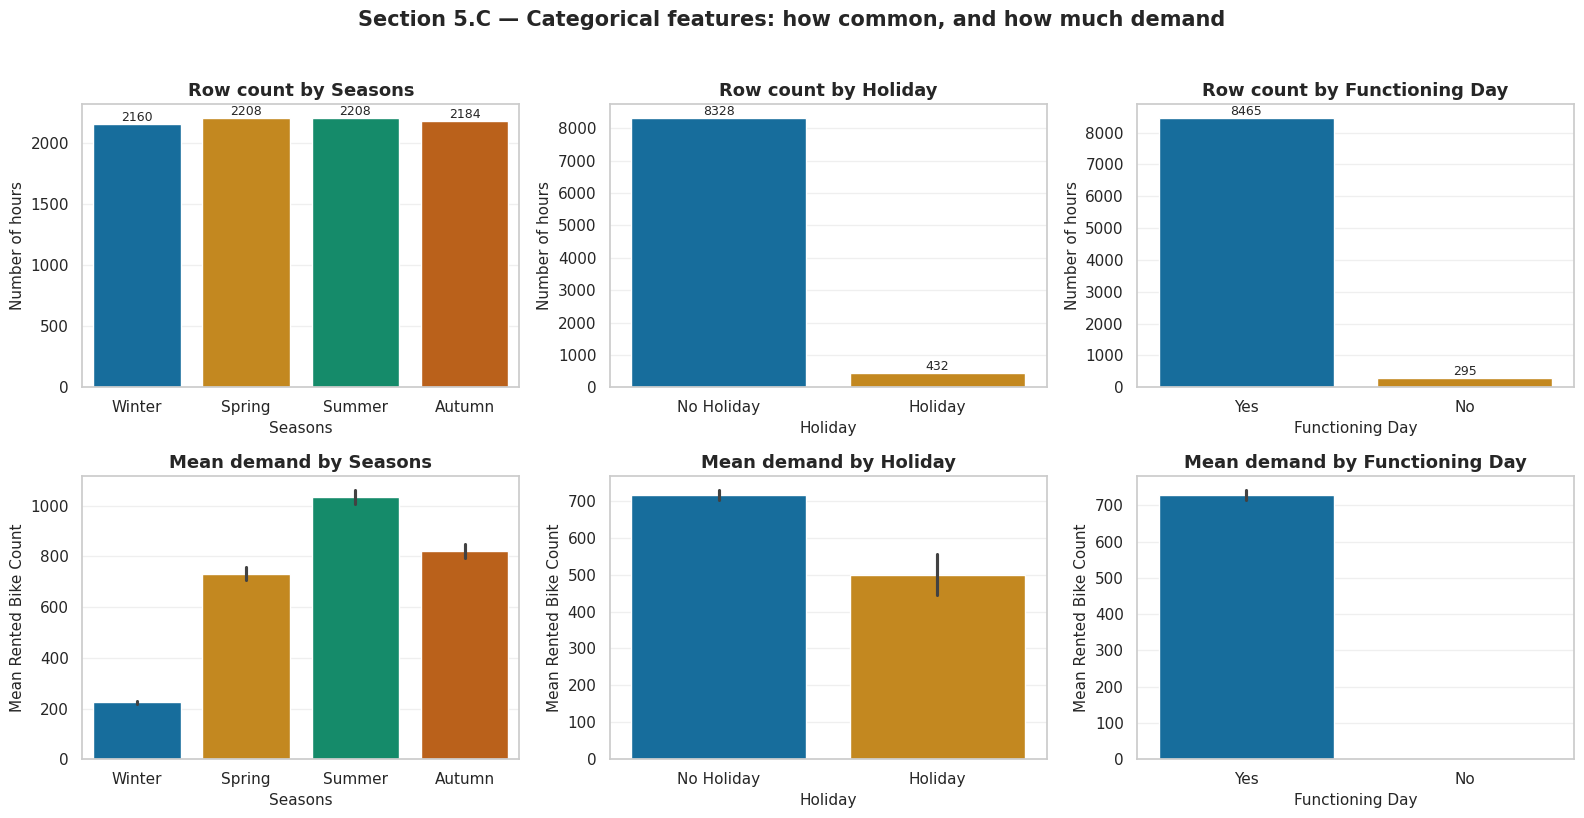

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, col in enumerate(CATEGORICAL_FEATURES):
    order = (bike_df[col].value_counts().index.tolist()
             if col != "Seasons" else ["Winter", "Spring", "Summer", "Autumn"])
    sns.countplot(data=bike_df, x=col, order=order, hue=col, legend=False,
                  palette="colorblind", ax=axes[0, i])
    axes[0, i].set_title(f"Row count by {col}")
    axes[0, i].set_ylabel("Number of hours")
    for container in axes[0, i].containers:
        axes[0, i].bar_label(container, fmt="%d", fontsize=9)

    sns.barplot(data=bike_df, x=col, y=TARGET, order=order, hue=col, legend=False,
                palette="colorblind", errorbar=("ci", 95), ax=axes[1, i])
    axes[1, i].set_title(f"Mean demand by {col}")
    axes[1, i].set_ylabel("Mean Rented Bike Count")

fig.suptitle("Section 5.C — Categorical features: how common, and how much demand",
             y=1.02, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("reg_eda_categorical", fig)
plt.show()

In [6]:
for col in CATEGORICAL_FEATURES:
    section(f"MEAN DEMAND BY {col.upper()}")
    print(
        bike_df.groupby(col, observed=True)[TARGET]
        .agg(Hours="count", Mean="mean", Median="median", Std="std", Max="max")
        .round(1)
        .to_string()
    )
    print()

MEAN DEMAND BY SEASONS
         Hours    Mean  Median    Std   Max
Seasons                                    
Autumn    2184   819.6   763.5  651.1  3298
Spring    2208   730.0   583.0  621.5  3251
Summer    2208  1034.1   905.5  690.2  3556
Winter    2160   225.5   203.0  150.4   937

MEAN DEMAND BY HOLIDAY
            Hours   Mean  Median    Std   Max
Holiday                                      
Holiday       432  499.8   240.0  570.8  2400
No Holiday   8328  715.2   524.5  646.9  3556

MEAN DEMAND BY FUNCTIONING DAY
                 Hours   Mean  Median    Std   Max
Functioning Day                                   
No                 295    0.0     0.0    0.0     0
Yes               8465  729.2   542.0  642.4  3556



**Observation.**

* **Seasons:** Summer averages roughly 1,034 rentals per hour, Winter roughly
  226 — a gap of about **4.6×**. Spring and Autumn sit in between and are close
  to each other.
* **Holiday:** holiday hours average around 500 versus around 715 on ordinary
  days, but holidays are only ~4% of rows, so the confidence interval is wider.
* **Functioning Day:** the "No" bar is exactly zero with no error bar at all.

**Interpretation.** Season is a strong, genuinely predictive signal — but it is
partly a **proxy for temperature**, which we already have as a continuous
feature. We will keep both and let the correlation analysis and the model's
feature importances tell us whether `Seasons` adds anything beyond temperature.

The `Functioning Day` bar visually confirms the structural finding from
Notebook 02: a bar with zero height and zero variance is a deterministic rule,
not a behavioural pattern. Notebook 04 removes those rows.

---
## 5.D Correlation analysis

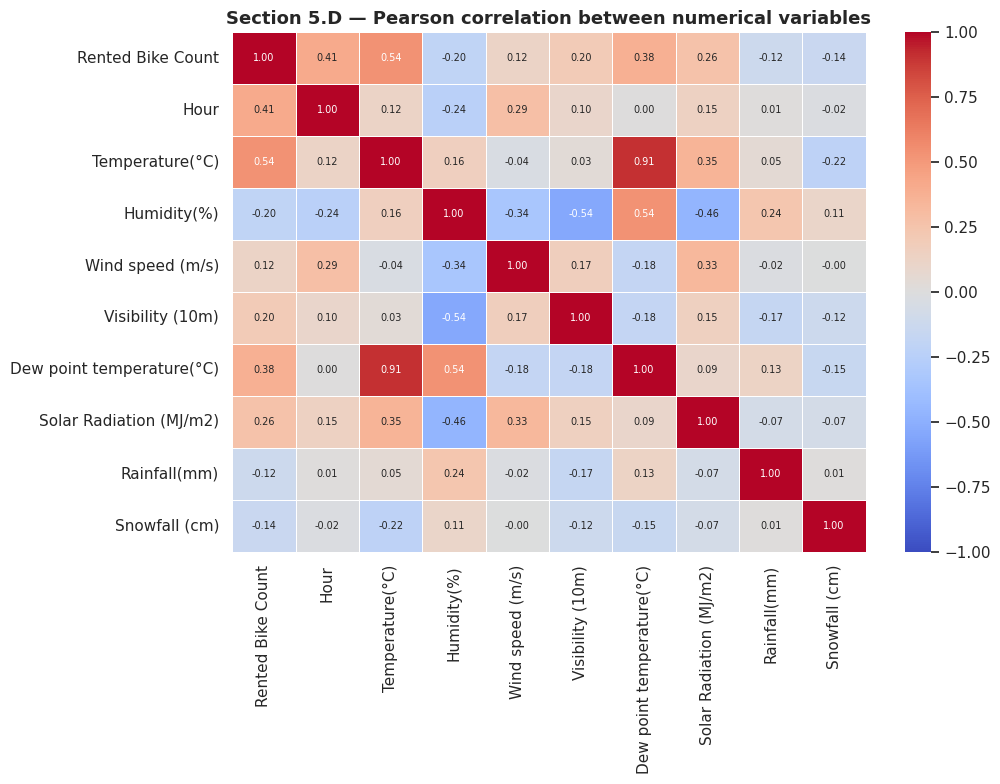

In [7]:
corr_frame = bike_df[[TARGET] + NUMERIC_FEATURES]
fig, corr = plot_correlation_heatmap(
    corr_frame,
    title="Section 5.D — Pearson correlation between numerical variables",
    figsize=(10.5, 8),
)
save_figure("reg_eda_correlation_heatmap", fig)
plt.show()

In [8]:
section("CORRELATION WITH THE TARGET (sorted by absolute strength)")
target_corr = (
    corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)
)
print(target_corr.to_string())

# Flag multicollinearity among the predictors themselves.
section("STRONGLY CORRELATED FEATURE PAIRS (|r| > 0.5, predictors only)")
pred_corr = corr.drop(index=TARGET, columns=TARGET)
pairs = (
    pred_corr.where(np.triu(np.ones(pred_corr.shape), k=1).astype(bool))
    .stack()
    .rename("r")
    .reset_index()
    .rename(columns={"level_0": "Feature A", "level_1": "Feature B"})
)
strong = pairs.loc[pairs["r"].abs() > 0.5].sort_values("r", key=abs, ascending=False)
print(strong.round(3).to_string(index=False) if len(strong) else "None found.")

CORRELATION WITH THE TARGET (sorted by absolute strength)
Temperature(°C)              0.539
Hour                         0.410
Dew point temperature(°C)    0.380
Solar Radiation (MJ/m2)      0.262
Humidity(%)                 -0.200
Visibility (10m)             0.199
Snowfall (cm)               -0.142
Rainfall(mm)                -0.123
Wind speed (m/s)             0.121
STRONGLY CORRELATED FEATURE PAIRS (|r| > 0.5, predictors only)
      Feature A                 Feature B      r
Temperature(°C) Dew point temperature(°C)  0.913
    Humidity(%)          Visibility (10m) -0.543
    Humidity(%) Dew point temperature(°C)  0.537


**Observation.**

* `Temperature(°C)` has the strongest linear association with demand
  (r ≈ **+0.54**), followed by `Hour` (≈ +0.41) and `Dew point temperature`
  (≈ +0.38). `Humidity` is the strongest negative (≈ −0.20).
* `Rainfall` and `Snowfall` show surprisingly *weak* linear correlations
  (|r| < 0.13).
* Among the predictors, `Temperature` and `Dew point temperature` are
  correlated at r ≈ **+0.91**.

**Interpretation.** Three points, and the second is the important one:

1. Temperature is the single most useful weather variable — warm weather,
   more cycling. Unsurprising, and reassuring that the data behaves sensibly.
2. **Weak correlation is not the same as weak importance.** Pearson's r only
   measures *straight-line* association. `Hour` is the clearest case: demand
   peaks twice a day (morning and evening commutes) and collapses overnight,
   which is a strongly predictive but profoundly non-linear pattern that r
   almost entirely misses. The same applies to rainfall, where the effect is a
   step rather than a slope. **We must not discard features on the basis of a
   low r.** Section 5.F below demonstrates this directly.
3. The Temperature/Dew-point pair is near-**collinear**. For Linear, Ridge,
   Lasso and ElasticNet this destabilises the individual coefficients (the
   model cannot tell which of the two deserves credit), so those coefficients
   must be interpreted with caution. Ridge and ElasticNet are specifically
   designed to cope with this, which is one reason the assignment includes
   them. Tree-based models are essentially unaffected. We keep both features
   and revisit the issue in Notebook 09.

---
## 5.E Feature-vs-target relationships

The rubric requires at least two scatter plots showing feature-target
relationships; we show four, chosen to cover the strongest linear signal, the
strongest non-linear signal, and two weather effects.

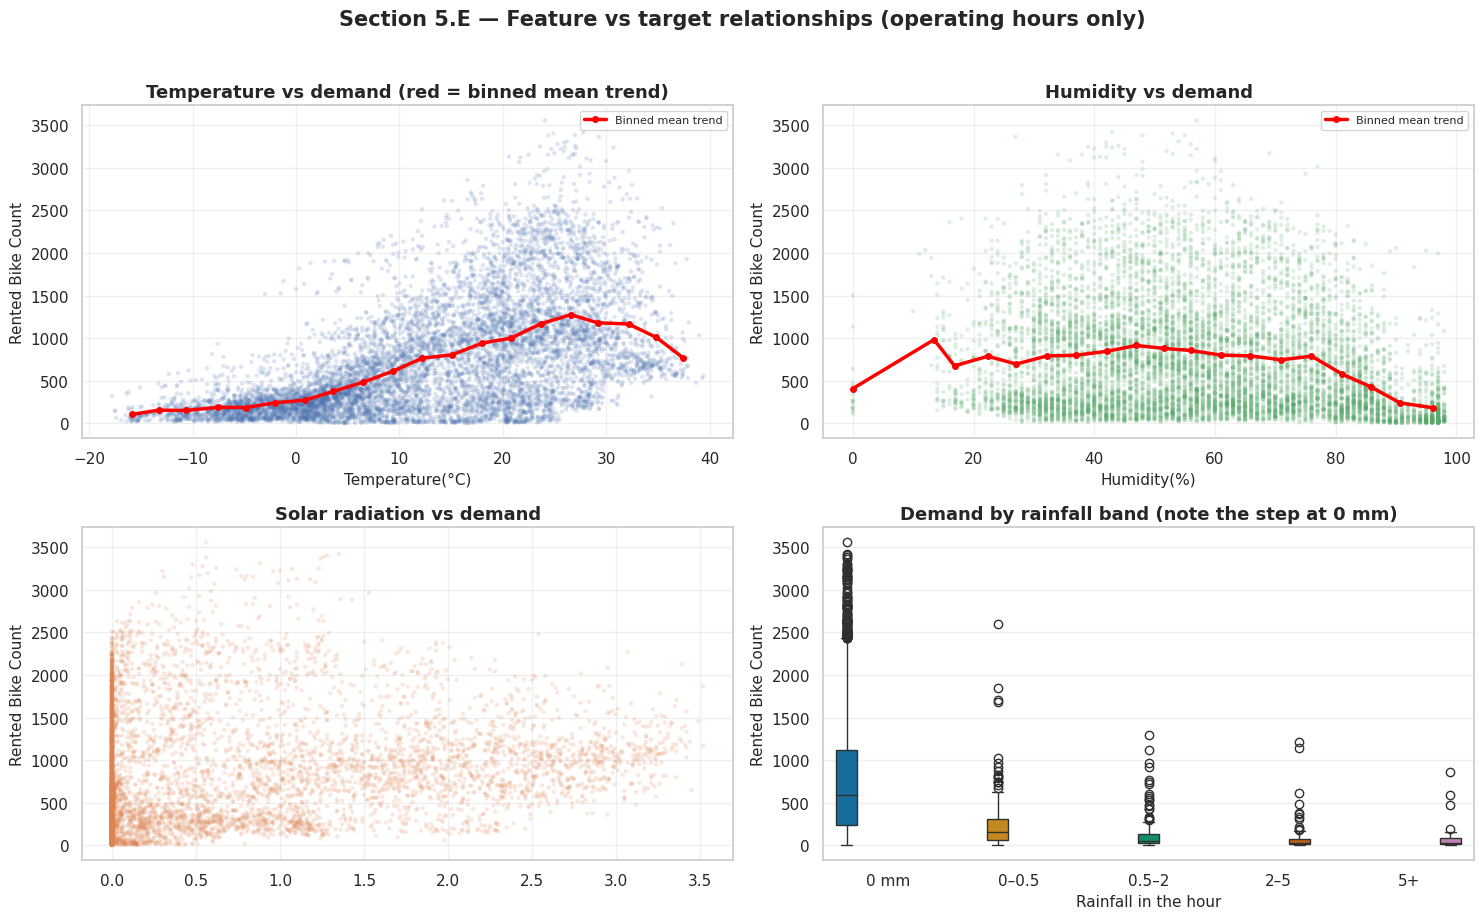

In [9]:
operating = bike_df[bike_df["Functioning Day"] == "Yes"]  # exclude closed hours

def binned_trend(ax, x, y, bins=20, color="red", label="Binned mean trend"):
    """Overlay a non-parametric trend line: mean of y within equal-width x bins.

    This is a dependency-light stand-in for a LOWESS smoother. It makes the
    *shape* of the relationship visible without assuming it is a straight line.
    """
    cut = pd.cut(x, bins=bins)
    grouped = pd.DataFrame({"x": x, "y": y, "bin": cut}).groupby("bin", observed=True)
    centres = grouped["x"].mean()
    means = grouped["y"].mean()
    ax.plot(centres, means, color=color, lw=2.5, marker="o", markersize=4, label=label)
    ax.legend(fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(15, 9))

axes[0, 0].scatter(operating["Temperature(°C)"], operating[TARGET],
                   alpha=0.18, s=10, edgecolor="none", color="#4C72B0")
binned_trend(axes[0, 0], operating["Temperature(°C)"], operating[TARGET])
axes[0, 0].set_title("Temperature vs demand (red = binned mean trend)")
axes[0, 0].set_xlabel("Temperature(°C)")
axes[0, 0].set_ylabel("Rented Bike Count")

axes[0, 1].scatter(operating["Humidity(%)"], operating[TARGET],
                   alpha=0.18, s=10, edgecolor="none", color="#55A868")
binned_trend(axes[0, 1], operating["Humidity(%)"], operating[TARGET])
axes[0, 1].set_title("Humidity vs demand")
axes[0, 1].set_xlabel("Humidity(%)")
axes[0, 1].set_ylabel("Rented Bike Count")

axes[1, 0].scatter(operating["Solar Radiation (MJ/m2)"], operating[TARGET],
                   alpha=0.18, s=10, edgecolor="none", color="#DD8452")
axes[1, 0].set_title("Solar radiation vs demand")
axes[1, 0].set_ylabel("Rented Bike Count")

rain_bins = pd.cut(operating["Rainfall(mm)"],
                   bins=[-0.01, 0.0001, 0.5, 2, 5, 40],
                   labels=["0 mm", "0–0.5", "0.5–2", "2–5", "5+"])
sns.boxplot(x=rain_bins, y=operating[TARGET], hue=rain_bins, legend=False,
            palette="colorblind", ax=axes[1, 1])
axes[1, 1].set_title("Demand by rainfall band (note the step at 0 mm)")
axes[1, 1].set_xlabel("Rainfall in the hour")
axes[1, 1].set_ylabel("Rented Bike Count")

fig.suptitle("Section 5.E — Feature vs target relationships (operating hours only)",
             y=1.02, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("reg_eda_feature_vs_target", fig)
plt.show()

In [10]:
section("MEAN DEMAND BY RAINFALL BAND")
print(
    operating.assign(Band=rain_bins)
    .groupby("Band", observed=True)[TARGET]
    .agg(Hours="count", Mean="mean", Median="median")
    .round(1)
    .to_string()
)

MEAN DEMAND BY RAINFALL BAND
       Hours   Mean  Median
Band                       
0 mm    7949  765.6   591.0
0–0.5    203  251.4   151.0
0.5–2    166  134.0    55.0
2–5       83  100.5    32.0
5+        64   73.3    24.0


**Observation.**

* **Temperature:** demand rises steadily up to roughly 25–30 °C, then the
  binned-mean curve **flattens and turns down** at the highest temperatures.
* **Humidity:** a mild downward trend, but the cloud is very wide — humidity
  alone explains little.
* **Solar radiation:** a dense vertical stripe at zero (night) spanning the
  whole range of demand, so the raw value is a poor standalone predictor.
* **Rainfall:** mean demand drops from about **766** bikes in dry hours to
  about **251** in the 0–0.5 mm band — it loses two-thirds of its volume at the
  very first drop of rain — and then declines much more gradually (134, 101, 73
  across the heavier bands).

**Interpretation.**

* The temperature curve is an **inverted U**, not a line. A straight-line model
  is structurally unable to capture "too hot is also bad". This is a concrete
  justification for including **Polynomial Regression** in the algorithm list,
  and for expecting trees and ensembles to do well.
* The rainfall boxplot explains the correlation puzzle from §5.D perfectly. The
  single biggest drop happens between "no rain" and "barely any rain"; going
  from 0.5 mm to 5 mm matters far less than going from 0 mm to 0.5 mm. That is a
  **threshold effect**, and Pearson's r — which is looking for a proportional
  slope across the whole range — reports it as only −0.12. Rainfall is genuinely
  important; correlation simply cannot see it.
* Solar radiation's vertical stripe at zero tells us it is only meaningful
  *given* the hour. That is an interaction, and it reinforces the plan to give
  the models good time features in Notebook 05.

---
## 5.F Time-based analysis

This is a demand-forecasting problem, so calendar structure deserves its own
section.

### 5.F.1 Hour of day

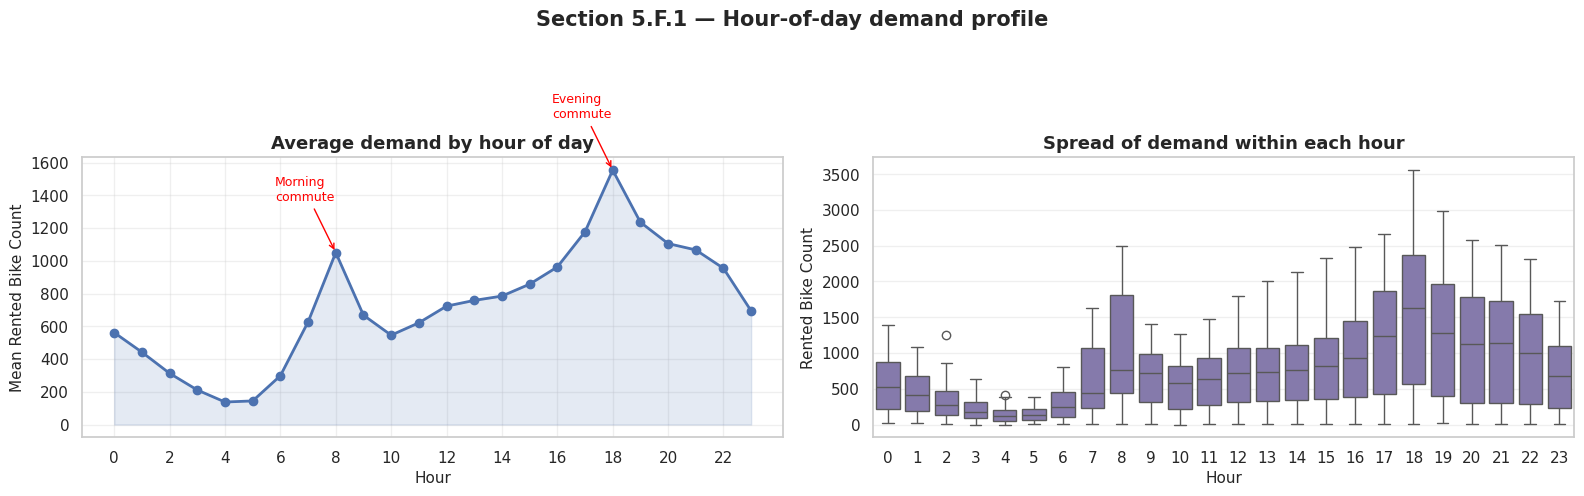

Quietest hour :  4:00  (137 bikes on average)
Busiest hour  : 18:00  (1554 bikes on average)
Peak-to-trough ratio: 11.3×


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

hourly = operating.groupby("Hour", observed=True)[TARGET].mean()
axes[0].plot(hourly.index, hourly.values, marker="o", lw=2, color="#4C72B0")
axes[0].fill_between(hourly.index, hourly.values, alpha=0.15, color="#4C72B0")
axes[0].set_title("Average demand by hour of day")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Mean Rented Bike Count")
axes[0].set_xticks(range(0, 24, 2))
for h, label in [(8, "Morning\ncommute"), (18, "Evening\ncommute")]:
    axes[0].annotate(label, xy=(h, hourly[h]), xytext=(h - 2.2, hourly[h] + 320),
                     arrowprops=dict(arrowstyle="->", color="red"), color="red", fontsize=9)

sns.boxplot(data=operating, x="Hour", y=TARGET, color="#8172B3", ax=axes[1])
axes[1].set_title("Spread of demand within each hour")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Rented Bike Count")

fig.suptitle("Section 5.F.1 — Hour-of-day demand profile",
             y=1.03, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("reg_eda_hourly", fig)
plt.show()

print(f"Quietest hour : {hourly.idxmin():>2}:00  ({hourly.min():.0f} bikes on average)")
print(f"Busiest hour  : {hourly.idxmax():>2}:00  ({hourly.max():.0f} bikes on average)")
print(f"Peak-to-trough ratio: {hourly.max() / hourly.min():.1f}×")

**Observation.** The hourly profile is a distinct **twin-peak (bimodal) curve**:
a sharp spike at 08:00, a trough through the middle of the day, and a much
larger spike at 18:00. The quietest hour (04:00) averages about **138** bikes;
the busiest (18:00) about **1,554** — an **11.3× swing** within a single day.
The boxplots also show that the spread grows with the mean: busy hours are not
just higher, they are far less predictable.

**Interpretation.** This is the single most important pattern in the dataset,
and it has three direct consequences for the modelling:

1. **`Hour` must not be treated as an ordinary linear number.** Linearly, hour 23
   is "23 units more" than hour 0, when in reality they are adjacent and both
   quiet. Notebook 05 therefore adds **cyclical sine/cosine encodings** so that
   23:00 and 00:00 sit next to each other in feature space.
2. The twin peaks correspond to commuting. A binary **rush-hour flag** is a
   logically justified engineered feature, not an arbitrary one.
3. The growing spread at peak hours is **heteroscedasticity** — non-constant
   error variance. It violates an assumption of ordinary least squares, and we
   should expect to see it again in the residual plot in Notebook 09. We
   predict now that we will find it there, and check later whether we did.

### 5.F.2 Month, season and the hour × season interaction

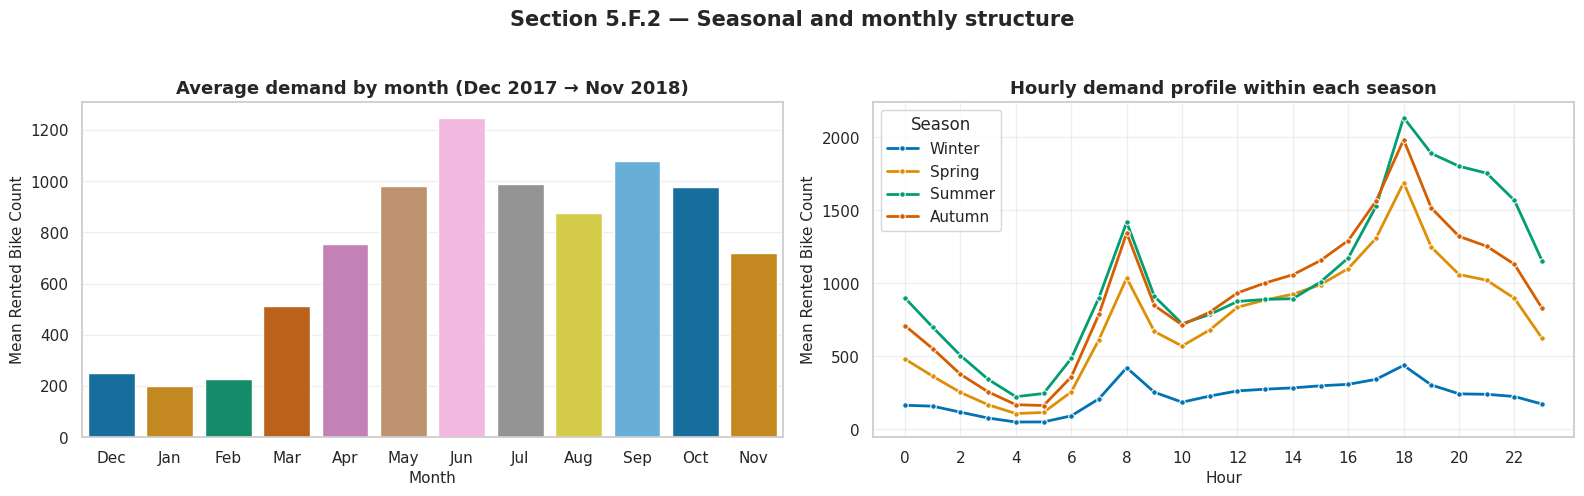

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

month_order = ["Dec", "Jan", "Feb", "Mar", "Apr", "May",
               "Jun", "Jul", "Aug", "Sep", "Oct", "Nov"]
monthly = operating.assign(MonthName=eda.loc[operating.index, "MonthName"])
sns.barplot(data=monthly, x="MonthName", y=TARGET, order=month_order,
            hue="MonthName", legend=False, palette="colorblind",
            errorbar=None, ax=axes[0])
axes[0].set_title("Average demand by month (Dec 2017 → Nov 2018)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Mean Rented Bike Count")

season_hour = operating.groupby(["Seasons", "Hour"], observed=True)[TARGET].mean().reset_index()
sns.lineplot(data=season_hour, x="Hour", y=TARGET, hue="Seasons",
             hue_order=["Winter", "Spring", "Summer", "Autumn"],
             palette="colorblind", lw=2, marker="o", markersize=4, ax=axes[1])
axes[1].set_title("Hourly demand profile within each season")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Mean Rented Bike Count")
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend(title="Season")

fig.suptitle("Section 5.F.2 — Seasonal and monthly structure",
             y=1.03, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("reg_eda_seasonal", fig)
plt.show()

**Observation.** Demand climbs from a winter minimum in January to a summer
maximum around June, dips slightly in the wettest part of mid-summer, recovers
in autumn, then collapses again in December. In the right-hand panel, **all
four seasons keep the same twin-peak shape** — the curves are scaled up and
down rather than reshaped.

**Interpretation.** Season acts as a **multiplier** on a stable daily rhythm,
not as a different rhythm. This is an interaction between hour and season, and
it matters for model choice: a purely additive linear model can only add a
fixed seasonal offset to every hour, which will overpredict winter evenings
and underpredict summer evenings. Tree ensembles model such interactions
automatically by splitting on season and hour in sequence, and polynomial
features can approximate it through cross terms. Another concrete, evidenced
reason to expect the non-linear models to win.

### 5.F.3 Weekday vs weekend, and holidays

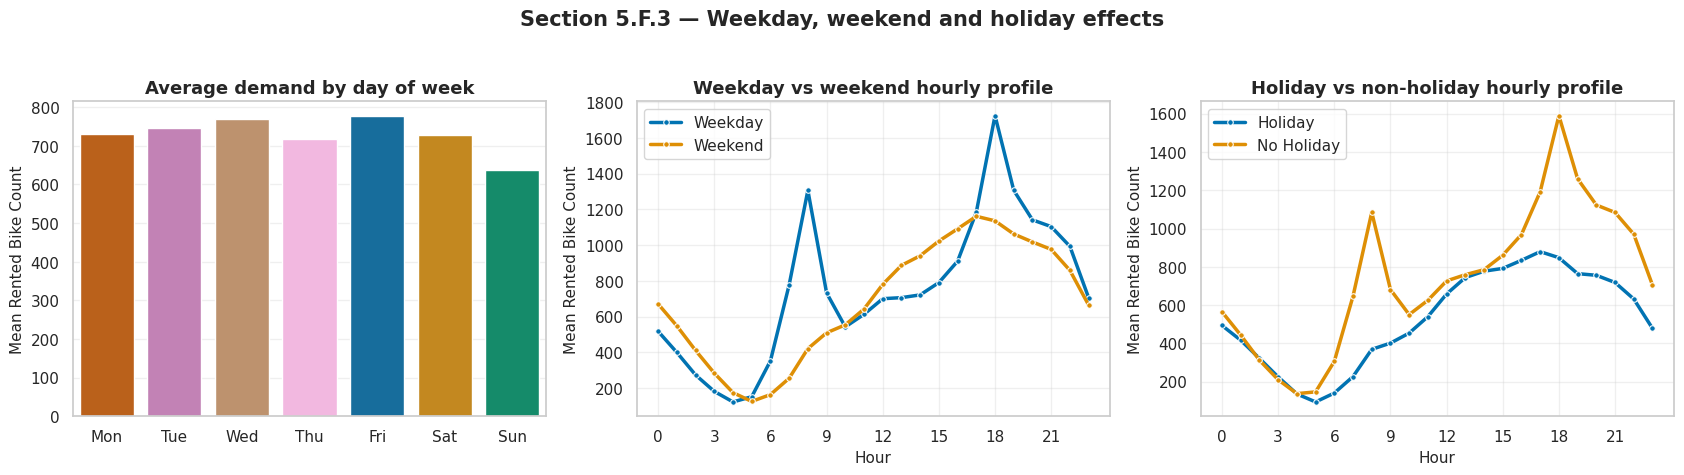

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

dow_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_frame = operating.assign(DayName=eda.loc[operating.index, "DayName"])
sns.barplot(data=dow_frame, x="DayName", y=TARGET, order=dow_order,
            hue="DayName", legend=False, palette="colorblind",
            errorbar=None, ax=axes[0])
axes[0].set_title("Average demand by day of week")
axes[0].set_xlabel("")
axes[0].set_ylabel("Mean Rented Bike Count")

we_frame = operating.assign(IsWeekend=eda.loc[operating.index, "IsWeekend"])
we_hour = we_frame.groupby(["IsWeekend", "Hour"], observed=True)[TARGET].mean().reset_index()
sns.lineplot(data=we_hour, x="Hour", y=TARGET, hue="IsWeekend",
             palette="colorblind", lw=2.5, marker="o", markersize=4, ax=axes[1])
axes[1].set_title("Weekday vs weekend hourly profile")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Mean Rented Bike Count")
axes[1].set_xticks(range(0, 24, 3))
axes[1].legend(title="")

hol_hour = operating.groupby(["Holiday", "Hour"], observed=True)[TARGET].mean().reset_index()
sns.lineplot(data=hol_hour, x="Hour", y=TARGET, hue="Holiday",
             palette="colorblind", lw=2.5, marker="o", markersize=4, ax=axes[2])
axes[2].set_title("Holiday vs non-holiday hourly profile")
axes[2].set_xlabel("Hour")
axes[2].set_ylabel("Mean Rented Bike Count")
axes[2].set_xticks(range(0, 24, 3))
axes[2].legend(title="")

fig.suptitle("Section 5.F.3 — Weekday, weekend and holiday effects",
             y=1.03, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("reg_eda_weekday_holiday", fig)
plt.show()

In [14]:
section("WEEKDAY VS WEEKEND — DEMAND AT KEY HOURS")
pivot = (
    we_frame[we_frame["Hour"].isin([8, 12, 18, 22])]
    .pivot_table(index="Hour", columns="IsWeekend", values=TARGET, aggfunc="mean")
    .round(0)
)
print(pivot.to_string())

WEEKDAY VS WEEKEND — DEMAND AT KEY HOURS
IsWeekend  Weekday  Weekend
Hour                       
8           1306.0    421.0
12           700.0    780.0
18          1724.0   1136.0
22           993.0    859.0


**Observation.** Daily totals differ only modestly across the week, but the
**shapes** differ sharply. On weekdays the 08:00 peak is pronounced; on
weekends it collapses — about **1,306** bikes at 08:00 on a weekday versus
about **421** on a weekend, a 3× difference at the same clock time. Midday runs
the other way (700 on weekdays versus 780 at 12:00 on weekends). The holiday
panel shows the same pattern in miniature.

**Interpretation.** There are two distinct user populations sharing one system:
**commuters** (sharp weekday morning peak, tied to work schedules) and
**leisure riders** (broad weekend afternoon plateau). A model given only
`Hour` cannot separate them, because 08:00 means two different things
depending on the day. This makes `IsWeekend` and `DayOfWeek` genuinely
informative engineered features rather than decorative ones — and it explains
why a plain weekly average would be a poor forecast.

### 5.F.4 The full year as a time series

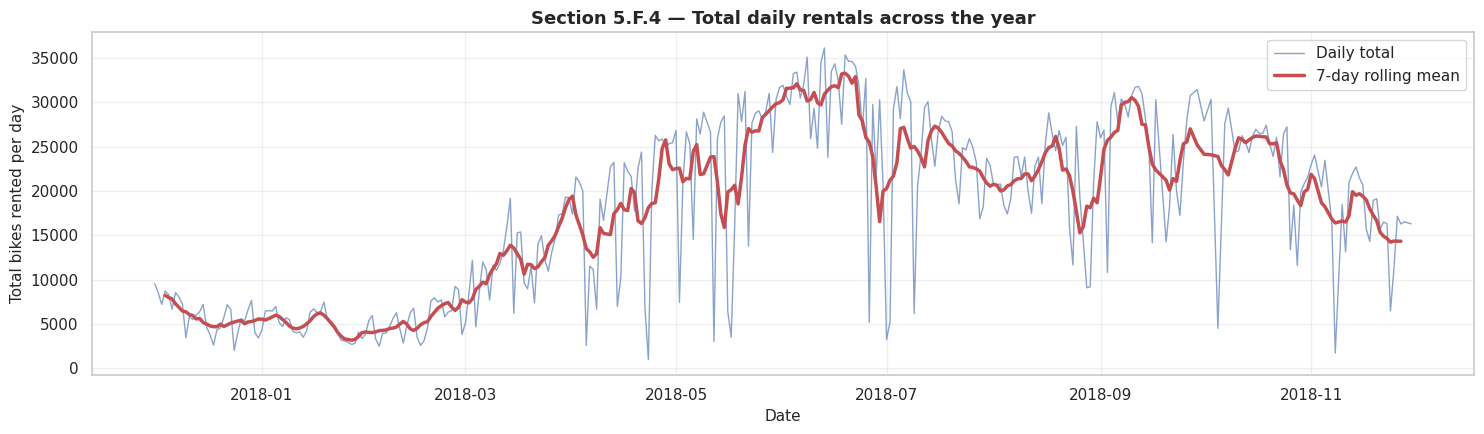

In [15]:
daily = (
    operating.assign(DateParsed=eda.loc[operating.index, "DateParsed"])
    .groupby("DateParsed", observed=True)[TARGET]
    .sum()
)

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(daily.index, daily.values, lw=1, color="#4C72B0", alpha=0.65,
        label="Daily total")
ax.plot(daily.index, daily.rolling(7, center=True).mean(), lw=2.5,
        color="#C44E52", label="7-day rolling mean")
ax.set_title("Section 5.F.4 — Total daily rentals across the year")
ax.set_xlabel("Date")
ax.set_ylabel("Total bikes rented per day")
ax.legend()
plt.tight_layout()
save_figure("reg_eda_timeseries", fig)
plt.show()

**Observation.** A clear annual cycle — low through December–February, rising
through spring, peaking in early summer, with sharp single-day collapses
scattered throughout (these coincide with heavy-rain days).

**Interpretation.** There is genuine **temporal autocorrelation**: today's
demand resembles yesterday's. That raises a methodological point worth stating
plainly. We use a standard **random** train/test split, as the assignment
specifies, which means training and test hours are interleaved in time. For a
production forecasting system a *chronological* split would be the honest
evaluation, because the real task is predicting the future from the past, and
a random split lets the model see hours from the same day on both sides. Our
reported R² is therefore best read as "how well the model explains demand
given weather and calendar conditions", not as "how well it would forecast
next month". We flag this as an explicit limitation in Notebook 09 rather than
quietly benefiting from it.

---
## 5.G EDA summary — what we take into modelling

| # | Finding | Consequence for the pipeline |
|---|---|---|
| 1 | Target is right-skewed with a long tail | Expect RMSE > MAE; keep raw target for comparability |
| 2 | Hour drives a 19× twin-peak swing | Add cyclical sin/cos hour + rush-hour flag (NB 05) |
| 3 | Temperature relationship is an inverted U | Polynomial and tree models justified |
| 4 | Rainfall acts as a threshold, not a slope | Explains its weak r; keep the feature |
| 5 | Season scales the daily profile (interaction) | Favours ensembles over additive linear models |
| 6 | Weekday and weekend have different shapes | Add `IsWeekend` / `DayOfWeek` (NB 05) |
| 7 | Temperature ≈ Dew point (r = 0.91) | Interpret linear coefficients cautiously; Ridge/ENet help |
| 8 | Weather features are zero-inflated, ranges differ hugely | Scaling required for KNN and SVR |
| 9 | Non-functioning hours are a deterministic zero | Remove in NB 04 |
| 10 | Strong temporal autocorrelation | Random split is a stated limitation |

**Overall hypothesis carried into Notebook 07:** non-linear models
(Random Forest, Gradient Boosting) should clearly beat the linear family on
this data. Notebook 07 tests that hypothesis rather than assuming it.

---
## Handover to Notebook 04

EDA changes no data. We pass the audited frame through unchanged.

In [16]:
save_artifact(bike_df, "reg_03_eda")

print("\nNotebook 03 complete.")
print("Next: 04_regression_outlier_analysis.ipynb")

[saved]  artifacts/reg_03_eda.joblib

Notebook 03 complete.
Next: 04_regression_outlier_analysis.ipynb
